In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from lightgbm import LGBMClassifier

file_path = '/kaggle/input/datasets/sonia27chowdary/loan-default-data/Loan_default.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully! Shape:", df.shape)
df.head()

Dataset loaded successfully! Shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [2]:
print("Column Info:")
df.info()

print("\nMissing Values Per Column:")
print(df.isnull().sum())

print("\nTarget Variable Distribution:")
print(df['Default'].value_counts(normalize=True))

Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 1

In [3]:
if 'LoanID' in df.columns:
    df = df.drop(columns=['LoanID'])

target_col = 'Default'
X = df.drop(columns=[target_col])
y = df[target_col]

numeric_features = [
    'Age', 'Income', 'LoanAmount', 'CreditScore', 
    'MonthsEmployed', 'NumCreditLines', 'InterestRate', 
    'LoanTerm', 'DTIRatio'
]

categorical_features = [
    'Education', 'EmploymentType', 'MaritalStatus', 
    'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner'
]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        scale_pos_weight=pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training model... Please wait.")
model.fit(X_train, y_train)
print("Training complete!")

Training model... Please wait.
[LightGBM] [Info] Number of positive: 23722, number of negative: 180555
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011959 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1330
[LightGBM] [Info] Number of data points in the train set: 204277, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116127 -> initscore=-2.029633
[LightGBM] [Info] Start training from score -2.029633
Training complete!


--- Classification Report (Threshold = 0.5) ---
              precision    recall  f1-score   support

           0       0.94      0.69      0.80     45139
           1       0.23      0.69      0.34      5931

    accuracy                           0.69     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.69      0.74     51070

ROC-AUC Score: 0.7573


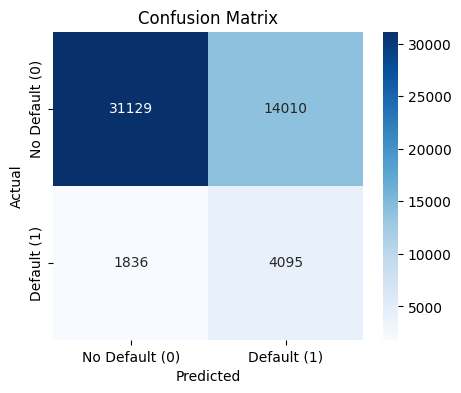

In [4]:
y_pred_proba = model.predict_proba(X_test)[:, 1]

threshold = 0.50
y_pred = (y_pred_proba >= threshold).astype(int)

print(f"--- Classification Report (Threshold = {threshold}) ---")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default (0)', 'Default (1)'],
            yticklabels=['No Default (0)', 'Default (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

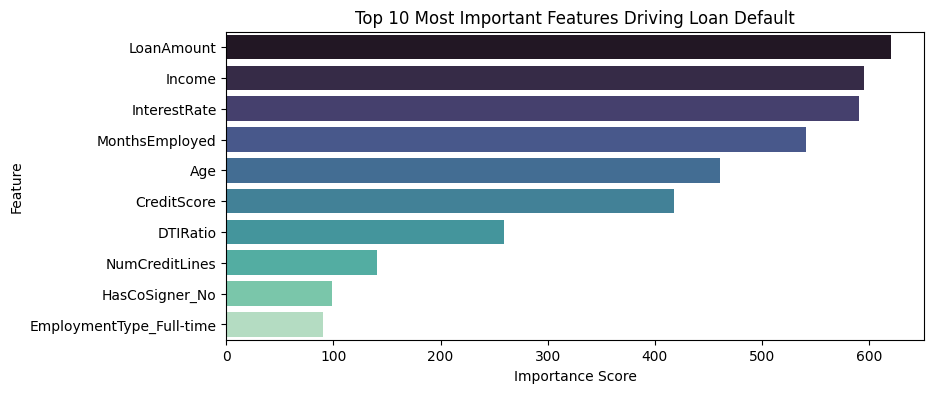

In [5]:
ohe=model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_encoded_names = ohe.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + cat_encoded_names

importances = model.named_steps['classifier'].feature_importances_
importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=importance_df.head(10), 
    x='Importance', 
    y='Feature', 
    hue='Feature', 
    palette='mako', 
    legend=False
)
plt.title('Top 10 Most Important Features Driving Loan Default')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

In [6]:
df_fe = df.copy()

df_fe['LoanToIncome'] = df_fe['LoanAmount'] / (df_fe['Income'] + 1)

df_fe['EstimatedMonthlyPayment'] = df_fe['LoanAmount'] / (df_fe['LoanTerm'] + 1)
df_fe['PaymentToIncomeRatio'] = df_fe['EstimatedMonthlyPayment'] / ((df_fe['Income'] / 12) + 1)

df_fe['CreditScoreTier'] = pd.cut(
    df_fe['CreditScore'],
    bins=[300, 580, 670, 740, 800, 850],
    labels=['Poor', 'Fair', 'Good', 'Very_Good', 'Exceptional']
)

engineered_numeric = numeric_features + ['LoanToIncome', 'EstimatedMonthlyPayment', 'PaymentToIncomeRatio']
engineered_categorical = categorical_features + ['CreditScoreTier']

X_fe = df_fe.drop(columns=['Default'])
y_fe = df_fe['Default']

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42, stratify=y_fe
)

preprocessor_fe = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, engineered_numeric),
        ('cat', categorical_transformer, engineered_categorical)
    ]
)
print("Feature Engineering complete!")

Feature Engineering complete!


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

models_dict = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=150, learning_rate=0.05, scale_pos_weight=pos_weight, random_state=42, n_jobs=-1)
}

results = []

for name, clf in models_dict.items():
    print(f"Training {name}...")
    pipe = Pipeline(steps=[('preprocessor', preprocessor_fe), ('classifier', clf)])
    pipe.fit(X_train_fe, y_train_fe)
    
    y_pred = pipe.predict(X_test_fe)
    y_prob = pipe.predict_proba(X_test_fe)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': round((y_pred == y_test_fe).mean(), 4),
        'Recall (Default)': round(recall_score(y_test_fe, y_pred), 4),
        'Precision (Default)': round(precision_score(y_test_fe, y_pred), 4),
        'F1-Score': round(f1_score(y_test_fe, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test_fe, y_prob), 4)
    })

comparison_df = pd.DataFrame(results)
print("\n--- Model Benchmark Comparison ---")
display(comparison_df)

Training Logistic Regression...
Training Random Forest...
Training LightGBM...
[LightGBM] [Info] Number of positive: 23722, number of negative: 180555
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006828 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2105
[LightGBM] [Info] Number of data points in the train set: 204277, number of used features: 39
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116127 -> initscore=-2.029633
[LightGBM] [Info] Start training from score -2.029633

--- Model Benchmark Comparison ---


,Model,Accuracy,Recall (Default),Precision (Default),F1-Score,ROC-AUC
0,Logistic Regression,0.6907,0.6984,0.2282,0.3440,0.7615
1,Random Forest,0.8855,0.0280,0.6748,0.0537,0.7347
2,LightGBM,0.6920,0.6909,0.2277,0.3426,0.7586


In [8]:
COST_FN = 10000
COST_FP = 1000

def compute_business_loss(y_true, y_prob, threshold):
    preds = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    total_cost = (fn * COST_FN) + (fp * COST_FP)
    return total_cost

thresholds = np.linspace(0.1, 0.9, 17)
costs = [compute_business_loss(y_test_fe, y_pred_proba, t) for t in thresholds]

optimal_t = thresholds[np.argmin(costs)]
print(f"Optimal Business Decision Threshold: {optimal_t:.2f} (Lowest Financial Loss)")

Optimal Business Decision Threshold: 0.45 (Lowest Financial Loss)


In [9]:
import joblib

best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_fe),
    ('classifier', models_dict['LightGBM'])
])
best_pipeline.fit(X_train_fe, y_train_fe)

joblib.dump(best_pipeline, 'loan_default_model.pkl')
print("Model saved to 'loan_default_model.pkl'!")

def predict_loan_application(applicant_data: dict, risk_threshold: float = optimal_t):
    
    model_loaded = joblib.load('loan_default_model.pkl')
    input_df = pd.DataFrame([applicant_data])

    default_prob = model_loaded.predict_proba(input_df)[0, 1]
    prediction = int(default_prob >= risk_threshold)
    
    return {
        "status": "success",
        "default_probability": round(float(default_prob), 4),
        "risk_decision": "REJECT / HIGH RISK" if prediction == 1 else "APPROVE / LOW RISK",
        "threshold_used": risk_threshold
    }

sample_applicant = {
    'Age': 28,
    'Income': 32000,
    'LoanAmount': 25000,
    'CreditScore': 590,
    'MonthsEmployed': 12,
    'NumCreditLines': 6,
    'InterestRate': 18.5,
    'LoanTerm': 36,
    'DTIRatio': 0.55,
    'Education': "Bachelor's",
    'EmploymentType': 'Unemployed',
    'MaritalStatus': 'Single',
    'HasMortgage': 'No',
    'HasDependents': 'No',
    'LoanPurpose': 'Auto',
    'HasCoSigner': 'No',
    'LoanToIncome': 25000 / 32001,
    'EstimatedMonthlyPayment': 25000 / 37,
    'PaymentToIncomeRatio': (25000 / 37) / ((32000 / 12) + 1),
    'CreditScoreTier': 'Fair'
}

api_response = predict_loan_application(sample_applicant)
print("\nAPI Response Output:")
print(api_response)

[LightGBM] [Info] Number of positive: 23722, number of negative: 180555
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007543 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2105
[LightGBM] [Info] Number of data points in the train set: 204277, number of used features: 39
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116127 -> initscore=-2.029633
[LightGBM] [Info] Start training from score -2.029633
Model saved to 'loan_default_model.pkl'!

API Response Output:
{'status': 'success', 'default_probability': 0.7632, 'risk_decision': 'REJECT / HIGH RISK', 'threshold_used': np.float64(0.45000000000000007)}
